# Vietnam Lubricant Demand Potential: Preliminary Model

**Capstone - Data Analytics track.** This notebook is the preliminary model file. It walks through every
pre-submission task on the real, official data:

| # | Task | Section |
|---|---|---|
| 1 | Problem framing | [1](#1.-Problem-framing) |
| 2 | Raw data & data cleaning | [2](#2.-Raw-data), [3](#3.-Data-cleaning) |
| 3 | Exploratory data analysis (EDA) | [4](#4.-Exploratory-data-analysis) |
| 4 | Feature engineering | [5](#5.-Feature-engineering) |
| 5 | Data transformation & storage | [6](#6.-Data-transformation-and-storage) |
| 6 | Model preparation | [7](#7.-Model-preparation) |
| 7 | Model assumption checks | [8](#8.-Model-assumption-checks) |
| 8 | Baseline model building | [9](#9.-Baseline-models) |

The production code lives in `src/vnlube/` (imported here), so the notebook and the automated pipeline
always use the same logic. The notebook shows *why* each step is done and what the data looks like at
each stage.

In [1]:
# --- setup -------------------------------------------------------------------------------
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)      # keep the output readable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

# project modules (installed in editable mode: pip install -e .)
from vnlube import config, transform, statistics, forecast, demand
from vnlube import data_access as da
from vnlube.figures import SEG_COLORS, SEG_LABEL, INK, INK2, GRID, SURFACE   # shared chart palette
from vnlube.ingest import raw_csv_path
from vnlube.jsonstat import read_jsonstat

# vnlube.figures switches matplotlib to the file-only "Agg" backend (for the pipeline);
# switch back so charts are displayed and saved inside the notebook
%matplotlib inline

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:,.3f}".format)
print("project root:", config.ROOT)

project root: C:\Users\FPT\Downloads\DA-BYOC-Starter-Package\vietnam-lubricant-demand


## 1. Problem framing

**Business problem.** The lubricant sales team sets provincial targets, distributor coverage and sales
headcount using national totals split by population share ("rule of thumb"). There is no defensible
estimate of how many litres of **motorbike oil (MCO)**, **passenger-car motor oil (PCMO)** and
**heavy-duty oil (HDMO)** each province can consume, or where demand is growing fastest. The estimate
also has to be redone by hand whenever the government publishes new statistics.

**Decision supported.** *Which provinces should get more sales and distributor effort, and with which
product focus?* This is reviewed quarterly by the national sales director, regional managers, distributor
development and marketing.

**Unit of analysis.** Province (34 provinces in force since 1 July 2025) x segment x year (2025 base,
forecast 2026-2028).

**Approach.** Lubricant demand is driven by the vehicle fleet:

$$\text{litres} = \text{fleet} \times \text{active share} \times \frac{\text{km per year}}{\text{km per oil change}}
\times \text{litres per change} \times \text{top-up factor}$$

Official province vehicle counts come from the NSO. The usage parameters are uncertain, so they are given
as ranges and propagated with Monte Carlo simulation.

**KPIs and success metrics** (defined before looking at results):

| KPI | Target |
|---|---|
| Demand potential by province x segment with a 95% interval | all 34 x 3 |
| Forecast accuracy of drivers on a 2023-2025 hold-out | national MAPE <= 10%, median province MAPE <= 15% |
| Model must beat simple baselines | lower hold-out error than naive / drift; provincial allocation that differs from population share where vehicles, income or freight differ |
| Refresh effort after an NSO release | < 15 minutes, no manual steps |

**Testable hypotheses** (on observed data only, alpha = 0.05, Holm-corrected):
* **H1** - vehicle density (vehicles per 1,000 people) differs between the 6 regions.
* **H2** - vehicle density increases with GRDP per capita (controlling for urbanisation).
* **H3** - provinces with lower vehicle density grow faster in real GRDP (catch-up headroom).

## 2. Raw data

All data come from the Vietnam National Statistics Office (NSO) PX-Web database and were downloaded by
`python -m vnlube.ingest`. Each table is archived **unchanged** in `data/raw/<sid>/<sid>.json` (the
original download) and as a flat `data/raw/<sid>/<sid>.csv` copy. The manifest records the URL, time
and SHA-256 hash of every download.

In [2]:
# The download manifest: one row per download attempt (latest attempt per source shown)
manifest = pd.read_csv(config.MANIFEST)
latest = manifest.sort_values("downloaded_at_utc").groupby("sid").tail(1)
latest[["sid", "table", "geography", "downloaded_at_utc", "cells", "status", "sha256"]].assign(
    sha256=lambda d: d["sha256"].str[:12] + "...")

,sid,table,geography,downloaded_at_utc,cells,status,sha256
15,p34_vehicles,PL.V14.59.px,p34,2026-11-22T10:09:57Z,164,unchanged,bccba48efece...
16,p34_accidents,PL.V14.55.px,p34,2026-11-22T10:10:16Z,126,unchanged,7331c87f60f8...
17,p34_population,PL.V02.02-04.px,p34,2026-11-22T10:10:17Z,1230,unchanged,3449171944bf...
18,p34_area,PL.V02.01.px,p34,2026-11-22T10:10:18Z,123,unchanged,9e272cc5785b...
19,p34_grdp_pc,PL.V03.02.px,p34,2026-11-22T10:10:19Z,246,unchanged,8d08561c495f...
20,p34_grdp_growth,PL.V03.01.px,p34,2026-11-22T10:10:19Z,246,unchanged,b5ae208dccc6...
21,p34_income,PL.V14.11.px,p34,2026-11-22T10:10:20Z,246,unchanged,a306b52e8297...
22,p34_road_passengers,PL.V12.03.px,p34,2026-11-22T10:10:21Z,246,unchanged,ba50f994458b...
23,p34_road_freight,PL.V12.07.px,p34,2026-11-22T10:10:21Z,246,unchanged,df7d068cff87...
24,p63_population,V02.03-07.px,p63,2026-11-22T10:10:22Z,11005,unchanged,7cb6a10442ff...


In [3]:
# Load every raw CSV exactly as published and summarise its shape, years and missing cells
summary = []
raw = {}
for src in config.SOURCES:
    df = pd.read_csv(raw_csv_path(src.sid), encoding="utf-8-sig")
    raw[src.sid] = df
    year_col = "Năm"
    summary.append({
        "sid": src.sid, "content": src.title_en[:60], "rows": len(df),
        "columns": ", ".join(c for c in df.columns if c not in ("value", "flag")),
        "periods": f"{df[year_col].iloc[0]} .. {df[year_col].iloc[-1]}",
        "missing_values": int(df["value"].isna().sum()),
    })
pd.DataFrame(summary)

,sid,content,rows,columns,periods,missing_values
0,p34_vehicles,Total vehicles (cars and motorbikes) and road-...,164,"Địa phương, Năm, Chỉ tiêu",2025 .. 2025,0
1,p34_accidents,"Road traffic accidents, deaths and injuries by...",126,"Địa phương, Năm, Chỉ tiêu",2025 .. 2025,1
2,p34_population,"Average population by province, sex and urban/...",1230,"Tỉnh, thành phố, Dân số trung bình, Năm",2020 .. Sơ bộ 2025,0
3,p34_area,"Area, average population and population densit...",123,"Địa phương, Năm, Chỉ tiêu",2025 .. 2025,0
4,p34_grdp_pc,"GRDP per capita by province (million VND, curr...",246,"Tỉnh, thành phố, Năm",2020 .. Ước tính 2025,0
5,p34_grdp_growth,GRDP growth index at constant 2010 prices by p...,246,"Tỉnh, thành phố, Năm",2020 .. Ước tính 2025,0
6,p34_income,Monthly income per capita by income quintile a...,246,"Địa phương, Năm, Nhóm thu nhập",Sơ bộ 2025 .. Sơ bộ 2025,0
7,p34_road_passengers,Road passengers carried by province,246,"Địa phương, Năm",2020 .. Sơ bộ 2025,0
8,p34_road_freight,Road freight carried by province,246,"Địa phương, Năm",2020 .. Sơ bộ 2025,0
9,p63_population,"Average population by province, sex and urban/...",11005,"Tỉnh, thành phố, Dân số trung bình, Năm",1995 .. Sơ bộ 2025,225


In [4]:
# The key table: registered vehicles (cars + motorbikes) by province, 2025 - as published
raw["p34_vehicles"].head(8)

,Địa phương,Năm,Chỉ tiêu,value,flag
0,CẢ NƯỚC,2025,Tổng phương tiện (ô tô và mô tô) (*) (Nghìn p...,"86,816.000",NaN
1,CẢ NƯỚC,2025,Số vụ tai nạn giao thông đường bộ trên 10.000 ...,2.127,NaN
2,CẢ NƯỚC,2025,Số người chết do tai nạn giao thông đường bộ t...,1.200,NaN
3,CẢ NƯỚC,2025,Số người bị thương do tai nạn giao thông đường...,1.413,NaN
4,Đồng bằng sông Hồng,2025,Tổng phương tiện (ô tô và mô tô) (*) (Nghìn p...,"20,418.600",NaN
5,Đồng bằng sông Hồng,2025,Số vụ tai nạn giao thông đường bộ trên 10.000 ...,2.160,NaN
6,Đồng bằng sông Hồng,2025,Số người chết do tai nạn giao thông đường bộ t...,1.186,NaN
7,Đồng bằng sông Hồng,2025,Số người bị thương do tai nạn giao thông đường...,1.474,NaN


## 3. Data cleaning

The raw tables are real and messy. The problems found, and how each is handled in `sql/02_clean.sql` /
`sql/03_marts.sql`:

| Problem in the raw data | Treatment |
|---|---|
| Two look-alike capital letters for Đ: `Đ` (U+0110) and `Ð` (U+00D0) | ASCII matching key `name_key()` |
| "TP. Hồ Chí Minh", "TP.Hồ Chí Minh", "Thừa Thiên Huế" vs "Huế" | prefix stripping + alias table |
| Year labels such as `Sơ bộ 2025` (preliminary), `Ước tính 2025` (estimate) | parse year + keep a data-status column |
| Region and national subtotal rows mixed with provinces | classify each row (national / region / province / unallocated) |
| `..` cells (no value) | classify as **structural** (unit did not exist) or **random** (interior gap -> interpolate) |
| 63 former provinces in the history, 34 since July 2025 | roll-up with an official merger map, validated against NSO's own 34-province figures |
| Urban/rural reclassification in 2025 | series-break table; models use the 2024 urban share |
| Implausible / extreme values | robust z-score screen (reported, not deleted) |

In [5]:
# Problem 1: the same region is spelled with two different capital D letters across tables
names = pd.concat([raw[s].iloc[:, 0] for s in ["p34_population", "p63_population"]]).drop_duplicates()
odd = names[names.str.contains("Ð")]          # U+00D0, the look-alike letter
print("labels using U+00D0 'Ð':", list(odd)[:6])
print("same text with U+0110 'Đ' exists?", any(n.replace("Ð", "Đ") in set(names) for n in odd))

labels using U+00D0 'Ð': ['Ðồng bằng sông Hồng', 'Nam Ðịnh', 'Ðiện Biên', 'Ðà Nẵng', 'Bình Ðịnh', 'Ðắk Lắk']
same text with U+0110 'Đ' exists? True


In [6]:
# Problem 2: period labels are not plain years
periods = pd.concat([raw[s]["Năm"].astype(str) for s in raw]).drop_duplicates()
print(sorted(p for p in periods if not p.isdigit()))

['Sơ bộ 2024', 'Sơ bộ 2025', 'Ước tính 2025']


In [7]:
# Problem 3: where are the missing values in the 63-province population history?
p63 = raw["p63_population"]
missing = p63[p63["value"].isna()]
missing.groupby("Tỉnh, thành phố")["Năm"].agg(["min", "max", "count"])
# -> all gaps are at the START (provinces split off in 2004) or END (Ha Tay merged into Ha Noi in 2008)
#    of a series: structural, not random. They must NOT be imputed.

,min,max,count
"Tỉnh, thành phố",,,
Hà Tây,2008,Sơ bộ 2025,90
Hậu Giang,1995,2003,45
Ðiện Biên,1995,2003,45
Ðắk Nông,1995,2003,45


In [8]:
# Build the warehouse: staging -> clean -> marts (runs sql/01..03 in DuckDB)
transform.run()
print(da.query("SELECT count(*) AS unmatched_labels FROM dq_unmatched_geography"))

   unmatched_labels
0                 0


In [9]:
# Missing-value classification produced by the SQL cleaning step
da.query("SELECT sid, geo_level, missing_type, n_cells, min_year, max_year, left(units, 70) AS units "
         "FROM dq_missingness ORDER BY sid")

,sid,geo_level,missing_type,n_cells,min_year,max_year,units
0,nat_industrial,national,random,79,1999,2007,CẢ NƯỚC
1,nat_industrial,national,structural,416,1995,2025,CẢ NƯỚC
2,p34_accidents,unallocated,structural,1,2025,2025,Khác
3,p63_population,province,structural,225,1995,2025,"Ðiện Biên, Ðắk Nông, Hà Tây, Hậu Giang"
4,p63_road_freight,province,structural,27,2000,2025,"Đắk Nông, Lai Châu, Hậu Giang, Hà Tây"
5,p63_road_passengers,province,random,1,2019,2019,Hòa Bình
6,p63_road_passengers,province,structural,27,2000,2025,"Hà Tây, Đắk Nông, Lai Châu, Hậu Giang"


In [10]:
# Validation of the 63 -> 34 province roll-up against the OFFICIAL 34-province series (2020-2025):
# if the merger map were wrong, these differences would be large.
rec = da.query("SELECT * FROM dq_reconciliation")
rec[["pop_diff_pct", "freight_diff_pct", "grdp_pc_diff_pct"]].abs().describe().loc[["count", "mean", "max"]]

,pop_diff_pct,freight_diff_pct,grdp_pc_diff_pct
count,204.000,204.000,198.000
mean,0.000,0.000,0.000
max,0.000,0.001,0.000


In [11]:
# Provinces must add up to the published regional and national vehicle totals
da.query("SELECT * FROM dq_vehicle_totals")

,level,unit,published_k,sum_of_provinces_k
0,national,CẢ NƯỚC,"86,816.000","86,816.000"
1,region,Đồng bằng sông Hồng,"20,418.600","20,418.600"
2,region,Trung du và miền núi phía Bắc,"9,163.500","9,163.500"
3,region,Bắc Trung Bộ,"8,417.800","8,417.800"
4,region,Duyên hải Nam Trung Bộ và Tây Nguyên,"14,776.700","14,776.700"
5,region,Đông Nam Bộ,"19,846.900","19,846.900"
6,region,Đồng bằng sông Cửu Long,"14,192.500","14,192.500"


In [12]:
# Series breaks: urban share jumps > 3 percentage points (2025 = administrative reform)
breaks = da.query("SELECT * FROM dq_series_breaks ORDER BY year DESC, abs(change_pp) DESC")
print(breaks["year"].value_counts().sort_index().to_dict())
breaks.head(8)

{2014: 1, 2015: 1, 2019: 2, 2020: 7, 2021: 2, 2022: 1, 2023: 1, 2025: 16}


,province_code,year,urban_share,prev_urban_share,change_pp,is_break
0,P20,2025,0.683,0.528,0.155,True
1,P04,2025,0.507,0.390,0.117,True
2,P07,2025,0.148,0.255,-0.106,True
3,P06,2025,0.322,0.228,0.094,True
4,P26,2025,0.265,0.346,-0.081,True
5,P32,2025,0.256,0.335,-0.079,True
6,P02,2025,0.435,0.360,0.075,True
7,P11,2025,0.169,0.236,-0.067,True


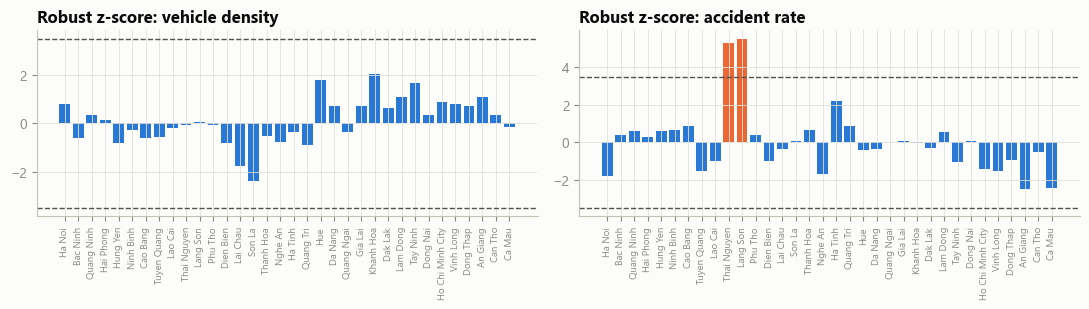

,province_code,province_en,vehicles_per_1000,accidents_per_10k,z_density,z_accident_rate,flag
9,P10,Thai Nguyen,789.506,5.188,-0.062,5.274,accident-rate outlier
10,P11,Lang Son,808.523,5.320,0.062,5.524,accident-rate outlier


In [13]:
# Outlier screen on the 2025 cross-section (robust z = (x - median) / (1.4826 * MAD))
base = da.province_base()
out = statistics.outliers(base)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for a, col, lab in [(ax[0], "z_density", "vehicle density"), (ax[1], "z_accident_rate", "accident rate")]:
    a.bar(out["province_en"], out[col], color=[SEG_COLORS["PCMO"] if abs(v) > 3.5 else SEG_COLORS["MCO"] for v in out[col]])
    a.axhline(3.5, color=INK2, ls="--", lw=1); a.axhline(-3.5, color=INK2, ls="--", lw=1)
    a.set_title(f"Robust z-score: {lab}"); a.tick_params(axis="x", rotation=90, labelsize=7)
plt.tight_layout(); plt.show()
out[out["flag"] != ""]
# Thai Nguyen and Lang Son have ~2.5x the national accident rate per vehicle. They are genuine
# official figures (not data errors) and do not enter the demand model, so they are kept and reported.

## 4. Exploratory data analysis

In [14]:
# Descriptive statistics of the 2025 province cross-section (n = 34)
cols = ["vehicles_k", "vehicles_per_1000", "population_k", "grdp_pc_mvnd", "urban_share_model",
        "road_freight_kt", "accidents_per_10k"]
base[cols].describe().T.assign(skew=base[cols].skew())

,count,mean,std,min,25%,50%,75%,max,skew
vehicles_k,34.000,"2,553.412","2,339.263",267.200,"1,251.750","2,458.650","3,050.000","12,873.300",3.061
vehicles_per_1000,34.000,812.504,145.032,435.721,712.955,799.015,908.592,"1,110.218",-0.196
population_k,34.000,"3,010.156","2,473.473",501.163,"1,614.517","2,918.331","3,553.704","13,803.797",2.932
grdp_pc_mvnd,34.000,103.951,46.093,49.587,78.815,88.833,111.172,261.202,1.841
urban_share_model,34.000,0.319,0.155,0.140,0.226,0.267,0.387,0.781,1.306
road_freight_kt,34.000,"67,702.455","72,702.374","2,157.440","17,936.753","43,893.888","80,299.016","269,622.197",1.704
accidents_per_10k,34.000,2.393,0.908,1.061,1.853,2.386,2.703,5.320,1.746


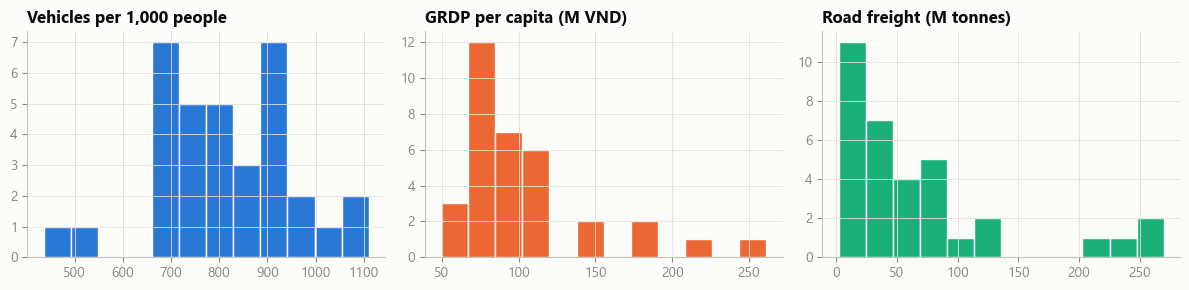

In [15]:
# Distributions: vehicle density is fairly symmetric; GRDP per capita and freight are right-skewed
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
ax[0].hist(base["vehicles_per_1000"], bins=12, color=SEG_COLORS["MCO"], edgecolor=SURFACE)
ax[0].set_title("Vehicles per 1,000 people")
ax[1].hist(base["grdp_pc_mvnd"], bins=12, color=SEG_COLORS["PCMO"], edgecolor=SURFACE)
ax[1].set_title("GRDP per capita (M VND)")
ax[2].hist(base["road_freight_kt"] / 1000, bins=12, color=SEG_COLORS["HDMO"], edgecolor=SURFACE)
ax[2].set_title("Road freight (M tonnes)")
plt.tight_layout(); plt.show()

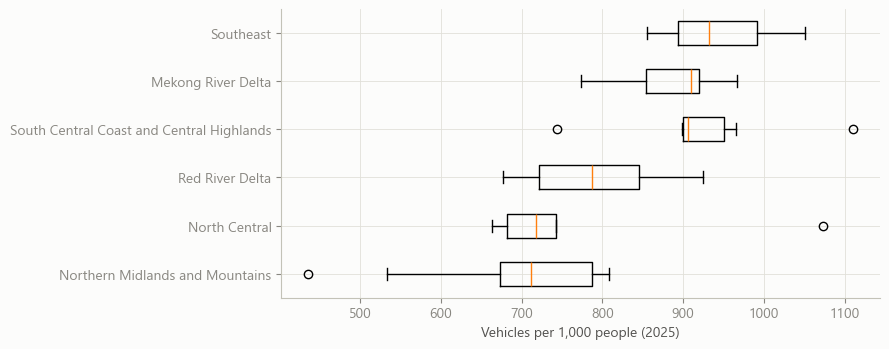

In [16]:
# Vehicle density by region (visual check for H1)
order = base.groupby("region_en")["vehicles_per_1000"].median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.boxplot([base.loc[base.region_en == r, "vehicles_per_1000"] for r in order], vert=False, widths=0.5)
ax.set_yticks(range(1, len(order) + 1), order)
ax.set_xlabel("Vehicles per 1,000 people (2025)")
plt.tight_layout(); plt.show()

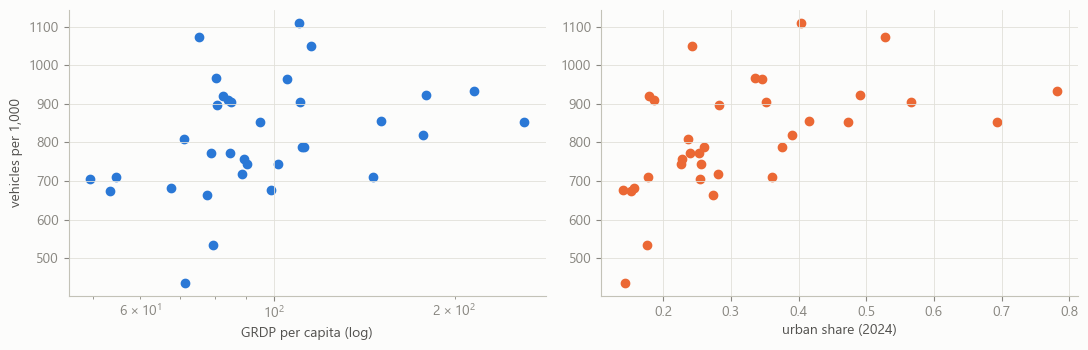

In [17]:
# Bivariate relationships (visual check for H2): density vs income and vs urbanisation
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].scatter(base["grdp_pc_mvnd"], base["vehicles_per_1000"], color=SEG_COLORS["MCO"])
ax[0].set_xscale("log"); ax[0].set_xlabel("GRDP per capita (log)"); ax[0].set_ylabel("vehicles per 1,000")
ax[1].scatter(base["urban_share_model"], base["vehicles_per_1000"], color=SEG_COLORS["PCMO"])
ax[1].set_xlabel("urban share (2024)")
plt.tight_layout(); plt.show()

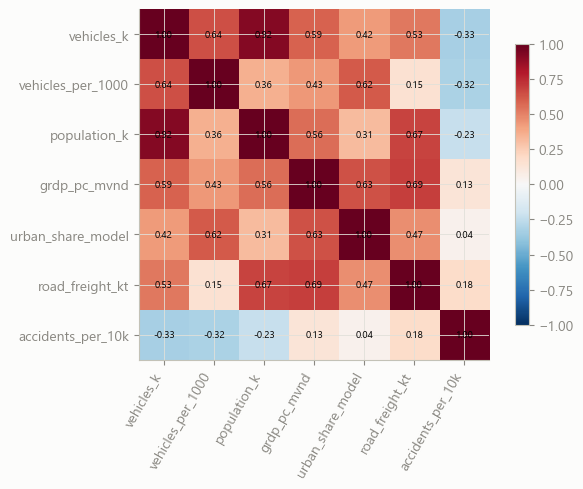

In [18]:
# Spearman correlation matrix (rank-based: robust to the skewed variables)
corr = base[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)          # diverging: blue <- 0 -> red
ax.set_xticks(range(len(cols)), cols, rotation=60, ha="right"); ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()
# Note: GRDP per capita and urban share are correlated (rho ~ 0.6), so income and urbanisation
# have to be separated in a multivariable model (H2) rather than judged from one scatter.

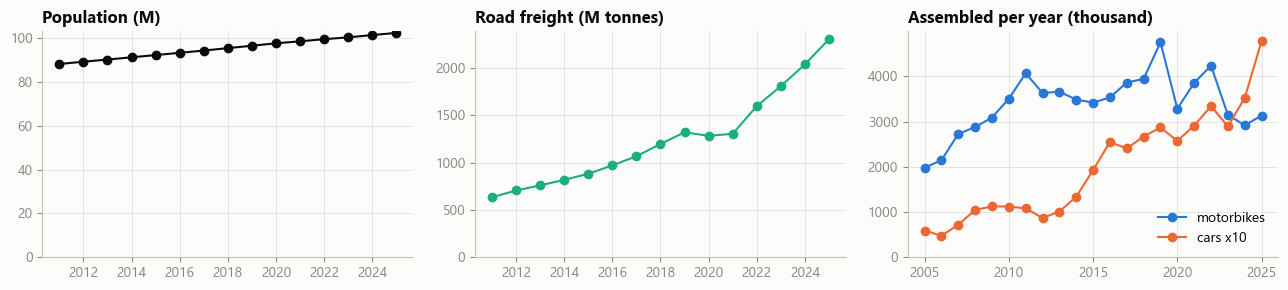

In [19]:
# National trends 2011-2025: population, road freight, and new vehicles assembled
py = da.province_year()
nat = py.groupby("year")[["population_k", "road_freight_kt"]].sum()
prod = da.query("SELECT * FROM mart_national_production WHERE year >= 2005")
fig, ax = plt.subplots(1, 3, figsize=(13, 3))
ax[0].plot(nat.index, nat["population_k"] / 1000, marker="o", color=INK); ax[0].set_title("Population (M)")
ax[1].plot(nat.index, nat["road_freight_kt"] / 1000, marker="o", color=SEG_COLORS["HDMO"]); ax[1].set_title("Road freight (M tonnes)")
ax[2].plot(prod["year"], prod["motorbikes_assembled_k"], marker="o", color=SEG_COLORS["MCO"], label="motorbikes")
ax[2].plot(prod["year"], prod["cars_assembled_k"] * 10, marker="o", color=SEG_COLORS["PCMO"], label="cars x10")
ax[2].set_title("Assembled per year (thousand)"); ax[2].legend()
for a in ax: a.set_ylim(0, None)
plt.tight_layout(); plt.show()
# Freight more than doubled since 2011 (HDMO driver); motorbike assembly has plateaued at ~3-4 M/yr
# since ~2011 (saturation); car assembly is still rising (PCMO driver).

In [20]:
# Which provinces' road freight grew fastest 2020 -> 2025 (official 34-province series)?
fr = py[py.year.isin([2020, 2025])].pivot(index="province_code", columns="year", values="road_freight_kt")
growth_fr = ((fr[2025] / fr[2020]) ** (1 / 5) - 1).rename("freight_cagr_2020_25")
growth_fr.to_frame().join(base.set_index("province_code")["province_en"]).sort_values(
    "freight_cagr_2020_25", ascending=False).head(8)

,freight_cagr_2020_25,province_en
province_code,,
P13,0.254,Dien Bien
P03,0.243,Quang Ninh
P06,0.181,Ninh Binh
P07,0.165,Cao Bang
P08,0.163,Tuyen Quang
P34,0.160,Ca Mau
P01,0.154,Ha Noi
P30,0.149,Vinh Long


## 5. Feature engineering

Features are derived from the cleaned marts. Each has a stated purpose:

| Feature | Definition | Used for |
|---|---|---|
| `vehicles_per_1000` | 1000 x vehicles / population | H1-H3 outcome; comparable across provinces of different size |
| `log_density`, `log_grdp` | natural logs | H2 regression (elasticity, reduces skew) |
| `urban_share_model` | urban / total population, **2024** | H2 control; avoids the 2025 reclassification break |
| `real_growth_22_25` | geometric mean of the official real GRDP index 2022-2025 | H3; income growth for the forecast |
| `rel_income` | GRDP per capita / national (population-weighted) | car allocation weight in the demand model |
| `freight_share` | province road freight / national | commercial-vehicle allocation |
| `freight_per_capita` | tonnes per person | EDA of HDMO intensity |

In [21]:
# Build the feature table (the production code computes the same features inside its functions)
feat = base.copy()
feat["log_density"] = np.log(feat["vehicles_per_1000"])
feat["log_grdp"] = np.log(feat["grdp_pc_mvnd"])
g_nat = np.average(feat["grdp_pc_mvnd"], weights=feat["population_k"])     # population-weighted national
feat["rel_income"] = feat["grdp_pc_mvnd"] / g_nat
feat["freight_share"] = feat["road_freight_kt"] / feat["road_freight_kt"].sum()
feat["freight_per_capita"] = feat["road_freight_kt"] / feat["population_k"]   # tonnes per person
feat = feat.join(statistics.real_growth(py).rename("real_growth_22_25"), on="province_code")
feat_cols = ["vehicles_per_1000", "log_density", "log_grdp", "urban_share_model", "real_growth_22_25",
             "rel_income", "freight_share", "freight_per_capita"]
feat[["province_en"] + feat_cols].head()

,province_en,vehicles_per_1000,log_density,log_grdp,urban_share_model,real_growth_22_25,rel_income,freight_share,freight_per_capita
0,Ha Noi,924.208,6.829,5.189,0.491,0.075,1.436,0.112,29.019
1,Bac Ninh,709.448,6.564,4.985,0.360,0.091,1.170,0.032,20.699
2,Quang Ninh,854.362,6.750,5.565,0.693,0.097,2.092,0.054,88.252
3,Hai Phong,818.700,6.708,5.176,0.390,0.102,1.417,0.099,54.928
4,Hung Yen,676.565,6.517,4.594,0.140,0.088,0.792,0.030,21.191


In [22]:
# Log transforms reduce skewness (closer to 0 = more symmetric), which suits linear regression
pd.DataFrame({
    "skew raw": [feat["grdp_pc_mvnd"].skew(), feat["vehicles_per_1000"].skew()],
    "skew log": [feat["log_grdp"].skew(), feat["log_density"].skew()],
}, index=["GRDP per capita", "vehicle density"])

,skew raw,skew log
GRDP per capita,1.841,0.788
vehicle density,-0.196,-0.939


In [23]:
# Engineered allocation feature: implied car share of each province's fleet at the most-likely
# assumptions (elasticity 1.0, 7.2 M cars nationally). Shown to sanity-check the allocation logic.
eps, C = 1.0, 7.2e6
w = feat["vehicles_k"] * feat["rel_income"] ** eps
feat["implied_cars_k"] = C / 1000 * w / w.sum()
feat["implied_car_share"] = feat["implied_cars_k"] / feat["vehicles_k"]
feat.sort_values("implied_car_share", ascending=False)[["province_en", "vehicles_k", "rel_income",
                                                        "implied_cars_k", "implied_car_share"]].head(6)
# Plausibility: reported figures for Ha Noi are roughly 0.7-1.1 M cars (press, 2024); the implied value
# above sits in that range, so the allocation feature behaves sensibly.

,province_en,vehicles_k,rel_income,implied_cars_k,implied_car_share
2,Quang Ninh,"1,206.000",2.092,204.920,0.170
28,Ho Chi Minh City,"12,873.300",1.724,"1,803.349",0.140
0,Ha Noi,"8,186.200",1.436,954.769,0.117
3,Hai Phong,"3,397.500",1.417,391.192,0.115
27,Dong Nai,"3,840.400",1.208,376.731,0.098
1,Bac Ninh,"2,534.400",1.170,240.963,0.095


## 6. Data transformation and storage

```
data/raw/<sid>.json  --(Python: JSON-stat -> long table)-->  stg_observation
        --(sql/01_reference.sql)--> ref_*  (provinces, 63->34 map, assumptions, benchmarks)
        --(sql/02_clean.sql)-->     cln_observation (typed years, status, geography, missing type), dq_*
        --(sql/03_marts.sql)-->     int_* (interpolation, roll-up) -> mart_* (analysis-ready) + dq_*
        --(pipeline.py)-->          res_* tables, dashboard/data/*.csv, data/processed/*.parquet
```

**Storage choices.** Raw JSON stays immutable for audit. DuckDB (a single file, in-process, SQL with window
functions) holds every layer. CSV feeds the dashboard and Power BI, and Parquet holds typed columnar copies
for analysis.

In [24]:
# Every table in the warehouse, grouped by layer
tables = da.query("SELECT table_name, estimated_size AS rows FROM duckdb_tables() ORDER BY table_name")
tables["layer"] = tables["table_name"].str.split("_").str[0]
tables.groupby("layer")["table_name"].agg(["count", lambda s: ", ".join(s)]).rename(
    columns={"count": "tables", "<lambda_0>": "names"})

,tables,names
layer,,
cln,2,"cln_observation, cln_series_bounds"
dq,6,"dq_bad_years, dq_missingness, dq_reconciliatio..."
int,3,"int_p34, int_p63_series, int_p63_to_34"
mart,5,"mart_dim_province, mart_national_production, m..."
ref,6,"ref_fleet_split_assumptions, ref_lubricant_ass..."
res,24,"res_assumption_checks, res_assumptions_fleet, ..."
stg,1,stg_observation


In [25]:
# The core of the name harmonisation (DuckDB macro in sql/01_reference.sql)
print((config.SQL_DIR / "01_reference.sql").read_text(encoding="utf-8").split("CREATE OR REPLACE TABLE")[0])
print(da.query("SELECT name_key('TP.Hồ Chí Minh') AS a, name_key('Thành phố Hồ Chí Minh') AS b, "
               "name_key('Ðiện Biên') AS c, name_key('Điện Biên') AS d"))

-- 01 Reference data and the name-normalisation macro --------------------------------------
-- Province names arrive in several spellings: "Đ" (U+0110) vs the look-alike "Ð" (U+00D0)
-- used in older NSO tables, "TP. Hồ Chí Minh" vs "Thành phố Hồ Chí Minh", "Thừa Thiên Huế"
-- vs "Huế", decomposed vs precomposed diacritics. Everything is matched on an ASCII key.

CREATE OR REPLACE MACRO name_key(s) AS
    regexp_replace(
        regexp_replace(
            lower(strip_accents(replace(replace(replace(replace(trim(s), 'Ð', 'D'), 'Đ', 'D'), 'đ', 'd'), 'ð', 'd'))),
            '^(tp\.\s*|tp\s+|thanh pho\s+)', ''),
        '[^a-z]', '', 'g');


           a          b         c         d
0  hochiminh  hochiminh  dienbien  dienbien


In [26]:
# The analysis-ready province-year mart (2011-2025, 34 provinces)
mart = da.query("SELECT * FROM mart_province_year")
print(mart.shape, "| years", mart.year.min(), "-", mart.year.max(),
      "| sources:", mart.geography_source.value_counts().to_dict())
mart[mart.province_code == "P01"].tail(4)

(510, 14) | years 2011 - 2025 | sources: {'rollup_63': 306, 'official_34': 204}


,province_code,year,population_k,urban_k,urban_share,grdp_pc_mvnd,real_grdp_index,road_freight_kt,road_passengers_m,income_pc_kvnd_month,geography_source,non_official_measures,has_imputed_values,rollup_complete
11,P01,2022,"8,435.652","4,138.505",0.491,141.122,108.959,"178,060.077","1,148.636",NaN,official_34,,False,True
12,P01,2023,"8,587.081","4,212.992",0.491,149.690,106.206,"209,318.006","1,419.836",NaN,official_34,,False,True
13,P01,2024,"8,717.629","4,280.835",0.491,162.924,106.536,"233,331.155","1,568.918",NaN,official_34,preliminary,False,True
14,P01,2025,"8,857.526","4,234.800",0.478,179.289,108.157,"257,036.035","1,907.805","8,374.250",official_34,"preliminary,estimate",False,True


In [27]:
# Storage footprint: raw downloads vs warehouse vs columnar exports
size = lambda p: sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1e6
print(f"raw JSON + CSV : {size(config.RAW):6.2f} MB")
print(f"DuckDB file    : {config.WAREHOUSE.stat().st_size / 1e6:6.2f} MB")
print(f"Parquet exports: {size(config.PROCESSED):6.2f} MB" if config.PROCESSED.exists() else "parquet: run the pipeline")

raw JSON + CSV :   1.06 MB
DuckDB file    :  17.84 MB
Parquet exports:   0.22 MB


## 7. Model preparation

Three model components are prepared:
1. **Hypothesis models** (H1-H3) on the 34-province cross-section.
2. **Driver forecasts** - a time-based split: train on years <= 2022 and test on 2023-2025 (no random
   split, which would leak future information).
3. **Monte Carlo demand model** - every uncertain assumption gets a documented triangular range.

In [28]:
# Assumption ranges (data/reference/*.csv) - every parameter has a rationale and/or a source
lube = da.triangular_table("ref_lubricant_assumptions")
split = da.triangular_table("ref_fleet_split_assumptions")
lube[["segment", "parameter", "low", "mode", "high", "unit"]]

,segment,parameter,low,mode,high,unit
0,MCO,active_share,0.700,0.800,0.900,share of registered
1,MCO,annual_km,"4,000.000","6,000.000","8,000.000",km/vehicle/year
2,MCO,drain_interval_km,"1,500.000","2,500.000","4,000.000",km
3,MCO,fill_litres,0.700,0.800,1.000,litres/change
4,MCO,other_fluids_factor,1.000,1.050,1.100,multiplier
5,PCMO,active_share,0.920,0.960,0.990,share of registered
6,PCMO,annual_km,"8,000.000","12,000.000","18,000.000",km/vehicle/year
7,PCMO,drain_interval_km,"5,000.000","7,500.000","10,000.000",km
8,PCMO,fill_litres,3.500,4.000,5.000,litres/change
9,PCMO,other_fluids_factor,1.050,1.100,1.200,multiplier


In [29]:
split[["parameter", "low", "mode", "high", "unit", "source"]]

,parameter,low,mode,high,unit,source
0,national_cars_2025,"6,800,000.000","7,200,000.000","7,600,000.000",vehicles,https://vietnamnews.vn/economy/1690616/only-ni...
1,passenger_share_of_cars,0.480,0.520,0.560,share,https://vietnamnews.vn/economy/1690616/only-ni...
2,car_income_elasticity,0.600,1.000,1.400,elasticity,assumption
3,commercial_freight_weight,0.300,0.500,0.700,weight,assumption
4,moto_density_income_elasticity,-0.100,0.050,0.250,elasticity,assumption
5,commercial_freight_elasticity,0.500,0.700,0.900,elasticity,assumption
6,car_density_income_elasticity,0.900,1.200,1.600,elasticity,assumption


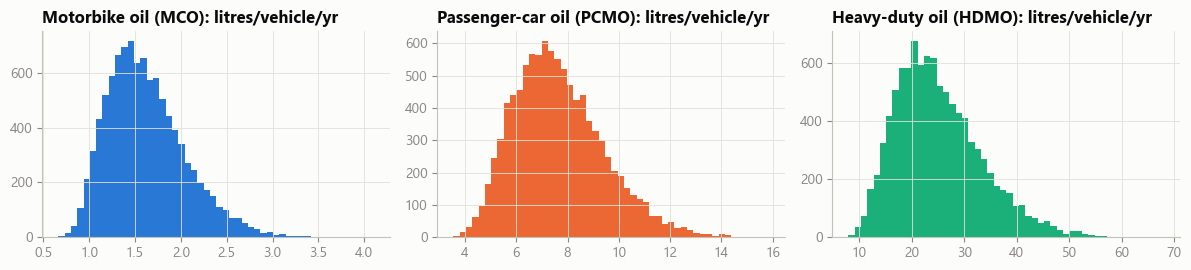

,MCO,PCMO,HDMO
p2.5,0.972,4.838,12.528
median,1.568,7.444,23.892
p97.5,2.602,11.589,44.357


In [30]:
# Implied litres per registered vehicle per year, by segment (distribution over 10,000 draws)
prm = demand.draw_parameters(lube, split, n=10_000, seed=2025)
lpv = {s: prm[f"{s}.active_share"] * prm[f"{s}.annual_km"] / prm[f"{s}.drain_interval_km"]
          * prm[f"{s}.fill_litres"] * prm[f"{s}.other_fluids_factor"] for s in demand.SEGMENTS}
fig, ax = plt.subplots(1, 3, figsize=(12, 2.8))
for a, s in zip(ax, demand.SEGMENTS):
    a.hist(lpv[s], bins=50, color=SEG_COLORS[s]); a.set_title(f"{SEG_LABEL[s]}: litres/vehicle/yr")
plt.tight_layout(); plt.show()
pd.DataFrame({s: np.percentile(v, [2.5, 50, 97.5]) for s, v in lpv.items()}, index=["p2.5", "median", "p97.5"])

In [31]:
# Time-based split used to evaluate the driver forecasts
print("train years:", py.year.min(), "-", forecast.BACKTEST_CUTOFF,
      "| test years:", forecast.BACKTEST_CUTOFF + 1, "-", config.BASE_YEAR,
      "| forecast:", config.BASE_YEAR + 1, "-", config.FORECAST_TO)

train years: 2011 - 2022 | test years: 2023 - 2025 | forecast: 2026 - 2028


In [32]:
# How many Monte Carlo draws are enough? Re-run with increasing n and watch the national median settle.
fc = forecast.run(py)
conv = []
for n in [250, 500, 1000, 2500, 5000, 10000]:
    r = demand.simulate(base, fc["drivers"], fc["growth"], lube, split, n=n, seed=11)
    tot = r.draws[:, :, :, 0].sum(axis=(1, 2)) / 1e6
    conv.append({"draws": n, "median_ML": np.median(tot), "p2.5": np.percentile(tot, 2.5), "p97.5": np.percentile(tot, 97.5)})
pd.DataFrame(conv)
# The median moves < 1% beyond ~2,500 draws; 10,000 draws are used (about 2 seconds).

,draws,median_ML,p2.5,p97.5
0,250,240.835,169.217,342.145
1,500,240.287,165.786,331.737
2,1000,242.438,172.133,343.273
3,2500,241.357,172.173,343.391
4,5000,242.062,173.155,349.324
5,10000,241.250,170.048,344.051


## 8. Model assumption checks

In [33]:
# Formal checks for the H1 (Kruskal-Wallis) and H2 (OLS) models
checks = statistics.assumption_checks(base)
checks

,model,assumption,check,statistic,p_value,passed,consequence
0,H2 OLS,Residuals normally distributed,Shapiro-Wilk,0.954,0.163,True,"If violated, rely on HC3 / bootstrap inference..."
1,H2 OLS,Residual skewness/kurtosis normal,Jarque-Bera,3.894,0.143,True,Large-sample normality check; complements Shap...
2,H2 OLS,Homoscedastic errors,Breusch-Pagan,1.700,0.427,True,HC3 robust standard errors are used either way
3,H2 OLS,Linear (log-log) functional form,Ramsey RESET,4.761,0.037,False,"If violated, add non-linear terms"
4,H2 OLS,No multicollinearity (log_grdp),VIF,2.136,NaN,True,VIF < 5 means coefficients are separately iden...
5,H2 OLS,No multicollinearity (urban_share_model),VIF,2.136,NaN,True,VIF < 5 means coefficients are separately iden...
6,H2 OLS,No single province drives the fit,Cook's D > 4/n (count),4.000,NaN,False,Robustness refit without influential provinces...
7,H2 OLS,Independent errors (north-south order),Durbin-Watson,1.068,NaN,False,Values near 2 mean no serial / spatial correla...
8,H1 Kruskal-Wallis,Similar spread across regions,"Brown-Forsythe (Levene, median)",0.173,0.970,True,"If violated, H1 is read as 'distributions diff..."
9,H1 Kruskal-Wallis,At least 3 observations per group,min group size,3.000,NaN,True,Chi-square approximation of H needs reasonable...


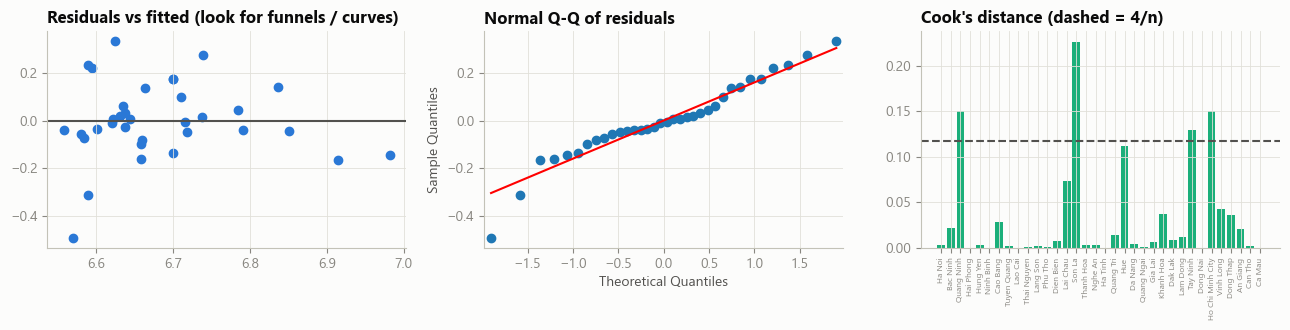

In [34]:
# Visual residual diagnostics for the H2 regression
y, X, d = statistics.h2_design(base)
ols = sm.OLS(y, X).fit()
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].scatter(ols.fittedvalues, ols.resid, color=SEG_COLORS["MCO"]); ax[0].axhline(0, color=INK2)
ax[0].set_title("Residuals vs fitted (look for funnels / curves)")
sm.qqplot(ols.resid, line="s", ax=ax[1]); ax[1].set_title("Normal Q-Q of residuals")
infl = ols.get_influence().cooks_distance[0]
ax[2].bar(d["province_en"], infl, color=SEG_COLORS["HDMO"]); ax[2].axhline(4 / len(d), color=INK2, ls="--")
ax[2].set_title("Cook's distance (dashed = 4/n)"); ax[2].tick_params(axis="x", rotation=90, labelsize=6)
plt.tight_layout(); plt.show()

**Remedy for the failed check.** The Ramsey RESET test flags that the log-log specification misses some
curvature. Before trusting the H2 conclusion ("income has no effect once urbanisation is controlled"), the
model is re-estimated with more flexible functional forms. If the income coefficient stays small and
non-significant in every one of them, the conclusion is robust to the misspecification.

In [35]:
# Alternative specifications for H2 (all with HC3 robust errors)
specs = {
    "baseline: log grdp + urban": ["log_grdp", "urban_share_model"],
    "+ urban^2":                  ["log_grdp", "urban_share_model", "urban_sq"],
    "+ log grdp^2":               ["log_grdp", "log_grdp_sq", "urban_share_model"],
    "log urban instead of urban": ["log_grdp", "log_urban"],
    "+ region fixed effects":     ["log_grdp", "urban_share_model"] + [c for c in pd.get_dummies(d["region_en"], prefix="r", drop_first=True, dtype=float).columns],
}
dd = d.assign(urban_sq=d["urban_share_model"] ** 2, log_grdp_sq=d["log_grdp"] ** 2,
              log_urban=np.log(d["urban_share_model"]))
dd = dd.join(pd.get_dummies(d["region_en"], prefix="r", drop_first=True, dtype=float))
rows = []
for name, xs in specs.items():
    m = sm.OLS(dd["log_density"], sm.add_constant(dd[xs])).fit(cov_type="HC3")
    reset_p = float(sm.stats.diagnostic.linear_reset(sm.OLS(dd["log_density"], sm.add_constant(dd[xs])).fit(),
                                                    power=2, use_f=True).pvalue)
    rows.append({"specification": name, "income coef": m.params["log_grdp"], "p (two-sided)": m.pvalues["log_grdp"],
                 "adj R2": m.rsquared_adj, "AIC": m.aic, "RESET p": reset_p})
pd.DataFrame(rows)
# Reading the table: in every LINEAR specification (incl. region fixed effects) the income coefficient
# is small and non-significant. In the quadratic specification the linear coefficient alone is NOT the
# income effect (the effect depends on the income level) - it is evaluated properly in the next cell.

,specification,income coef,p (two-sided),adj R2,AIC,RESET p
0,baseline: log grdp + urban,-0.030,0.762,0.229,-22.120,0.037
1,+ urban^2,-0.023,0.805,0.328,-25.906,0.432
2,+ log grdp^2,3.016,0.001,0.313,-25.126,0.229
3,log urban instead of urban,-0.068,0.461,0.328,-26.778,0.277
4,+ region fixed effects,-0.073,0.652,0.390,-26.033,0.003


squared term b2 = -0.330 (p = 0.0010) -> inverted U; turning point at GRDP per capita ~ 97 M VND (14 of 34 provinces above it)


,percentile,grdp_pc_mvnd,elasticity,p_value
0,10,68.596,0.228,0.037
1,50,88.832,0.058,0.490
2,90,168.693,-0.365,0.006


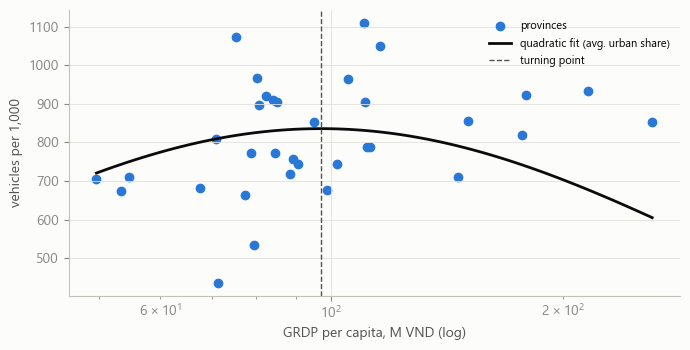

In [36]:
# Income effect in the quadratic specification, evaluated at low / median / high income
nl = statistics.h2_nonlinear(base)
print(f"squared term b2 = {nl['b_log_grdp_sq']:.3f} (p = {nl['p_sq']:.4f}) -> "
      f"{'inverted U' if nl['b_log_grdp_sq'] < 0 else 'U shape'}; "
      f"turning point at GRDP per capita ~ {nl['turning_point_grdp_pc']:.0f} M VND "
      f"({nl['n_above_turning']} of 34 provinces above it)")
display(pd.DataFrame(nl["elasticity_at"]))

# visualise: fitted density curve at the average urban share
grid = np.linspace(dd["log_grdp"].min(), dd["log_grdp"].max(), 100)
fit_q = sm.OLS(dd["log_density"], sm.add_constant(dd[["log_grdp", "log_grdp_sq", "urban_share_model"]])).fit()
pred = fit_q.params["const"] + fit_q.params["log_grdp"] * grid + fit_q.params["log_grdp_sq"] * grid ** 2 \
       + fit_q.params["urban_share_model"] * dd["urban_share_model"].mean()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.scatter(dd["grdp_pc_mvnd"], dd["vehicles_per_1000"], color=SEG_COLORS["MCO"], label="provinces")
ax.plot(np.exp(grid), np.exp(pred), color=INK, lw=2, label="quadratic fit (avg. urban share)")
ax.axvline(nl["turning_point_grdp_pc"], color=INK2, ls="--", lw=1, label="turning point")
ax.set_xscale("log"); ax.set_xlabel("GRDP per capita, M VND (log)"); ax.set_ylabel("vehicles per 1,000")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Interpretation of the assumption checks**

* **Normality, homoscedasticity, multicollinearity (H2) and equal spread (H1) pass.** The tests are
  used as intended.
* **Functional form (RESET) fails** for the linear H2 model. A squared income term removes the
  misspecification (RESET p > 0.05) and shows an **inverted U**. Vehicle density rises with income in
  poorer provinces, flattens around the median, and falls in the richest provinces, where cars replace
  motorbikes. The pre-registered *linear* H2 is still "not rejected". The inverted U is an
  **exploratory** finding, to be confirmed on the next data release rather than claimed as proven.
  Business meaning: in lower-income provinces, income growth still adds vehicles (mostly MCO); in rich
  provinces it shifts demand towards PCMO.
* **Independence (Durbin-Watson ~ 1.1) fails.** Neighbouring provinces have similar residuals (spatial
  correlation). Remedies used: region fixed effects and region-clustered standard errors (see
  `statistics.h2_income`, `p_cluster_region`). The linear income effect stays non-significant under both.
* **Influence:** 4 provinces exceed Cook's D > 4/n. The robustness refit without them is reported and
  does not change the conclusion.

In [37]:
# Forecast model checks: are the hold-out errors of the chosen method unbiased (no systematic over/under)?
bt = fc["backtest"]
for var, g in bt.groupby("variable"):
    m = g["chosen_method"].iloc[0]
    bias = (g[f"pred_test_sum_{m}"] / g["actual_test_sum"] - 1) * 100
    t, p = stats.ttest_1samp(bias, 0)
    print(f"{var:16s} method={m:10s} mean bias {bias.mean():+.2f}%  (t-test vs 0: p = {p:.3f})")
# Population forecasts are unbiased. Freight forecasts UNDER-predict: road freight accelerated in
# 2023-2025 faster than its long-run trend. The HDMO growth forecast is therefore conservative
# (a lower bound rather than a central estimate); this is stated in the findings.

population_k     method=drift      mean bias +0.15%  (t-test vs 0: p = 0.224)
road_freight_kt  method=drift      mean bias -12.23%  (t-test vs 0: p = 0.000)


In [38]:
# Monte Carlo checks: (1) the fleet split never produces a negative motorbike count,
# (2) results do not depend on the random seed, (3) the split conserves the official totals.
res = {s: demand.simulate(base, fc["drivers"], fc["growth"], lube, split, n=5000, seed=s) for s in [1, 2, 3]}
for s, r in res.items():
    mc_share = r.fleet[:, :, 0, 0] / r.fleet[:, :, :, 0].sum(axis=2)
    print(f"seed {s}: national median {np.median(r.draws[:, :, :, 0].sum(axis=(1, 2))) / 1e6:6.1f} M L | "
          f"min motorbike share of fleet {mc_share.min():.2f} | "
          f"fleet sum = official total: {np.allclose(r.fleet[:, :, :, 0].sum(axis=2), base.vehicles_k.values * 1000)}")

seed 1: national median  241.9 M L | min motorbike share of fleet 0.74 | fleet sum = official total: True
seed 2: national median  241.2 M L | min motorbike share of fleet 0.75 | fleet sum = official total: True
seed 3: national median  242.4 M L | min motorbike share of fleet 0.75 | fleet sum = official total: True


In [39]:
# Parameter independence: assumptions are sampled independently. Check that no two sampled
# parameters are accidentally correlated (|r| should be ~0 for independent draws).
pm = pd.DataFrame(res[1].params)
c = pm.corr().where(~np.eye(len(pm.columns), dtype=bool)).abs()
print("largest |correlation| between any two sampled parameters:", round(float(c.max().max()), 3))

largest |correlation| between any two sampled parameters: 0.045


## 9. Baseline models

A model only adds value if it beats simple alternatives. Three comparisons:

1. **Driver forecasts** - ETS vs naive (flat) vs drift on the 2023-2025 hold-out.
2. **H2 explanatory model** - leave-one-out cross-validation against a mean-only baseline.
3. **Demand model** - Monte Carlo vs (a) a deterministic point estimate, (b) the population-share rule of thumb.

In [40]:
# 9.1 Forecast baselines (median province MAPE and national MAPE on the hold-out)
bs = fc["backtest_summary"].set_index("variable")
bs

,chosen_method,median_province_mape_ets_damped,national_mape_ets_damped,median_province_mape_drift,national_mape_drift,median_province_mape_naive,national_mape_naive
variable,,,,,,,
population_k,drift,0.424,0.120,0.373,0.421,1.747,1.840
road_freight_kt,drift,20.869,15.146,13.277,6.852,23.274,22.127


In [41]:
# 9.2 Leave-one-out cross-validation for the density model: does adding predictors beat a
#     mean-only baseline? (LOO written by hand: each province is predicted by a model fitted on the other 33)
def loo_rmse(xcols):
    errs = []
    for i in range(len(dd)):
        train = dd.drop(dd.index[i]); test = dd.iloc[[i]]
        if xcols:
            m = sm.OLS(train["log_density"], sm.add_constant(train[xcols])).fit()
            pred = m.predict(sm.add_constant(test[xcols], has_constant="add"))
        else:
            pred = np.array([train["log_density"].mean()])     # baseline: predict the mean
        errs.append(float(test["log_density"].iloc[0] - np.asarray(pred)[0]))
    return float(np.sqrt(np.mean(np.square(errs))))

pd.DataFrame({"model": ["mean only (baseline)", "urban share", "income", "income + urban share",
                        "income + income^2 + urban share"],
              "LOO RMSE (log density)": [loo_rmse([]), loo_rmse(["urban_share_model"]),
                                         loo_rmse(["log_grdp"]), loo_rmse(["log_grdp", "urban_share_model"]),
                                         loo_rmse(["log_grdp", "log_grdp_sq", "urban_share_model"])]})
# Urban share alone beats the mean baseline; adding a LINEAR income term does not improve out-of-sample
# error (matches the linear H2 result). Whether the quadratic term generalises is shown in the last row.

,model,LOO RMSE (log density)
0,mean only (baseline),0.194
1,urban share,0.172
2,income,0.184
3,income + urban share,0.175
4,income + income^2 + urban share,0.162


In [42]:
# 9.3 Full Monte Carlo run and comparison with both demand baselines
sim = demand.simulate(base, fc["drivers"], fc["growth"], lube, split, n=10_000)
summ = demand.summarise(sim, base)
cmp, metrics = demand.compare_baselines(base, fc["drivers"], fc["growth"], lube, split, summ)
pd.Series(metrics).round(2)

national_mc_median_ML                   240.740
national_deterministic_ML               225.530
mc_vs_deterministic_pct                   6.740
spearman_model_vs_population_share        0.950
mean_abs_diff_vs_population_share_pct    20.450
max_abs_diff_vs_population_share_pct     71.670
top10_changed_vs_population_share         2.000
dtype: float64

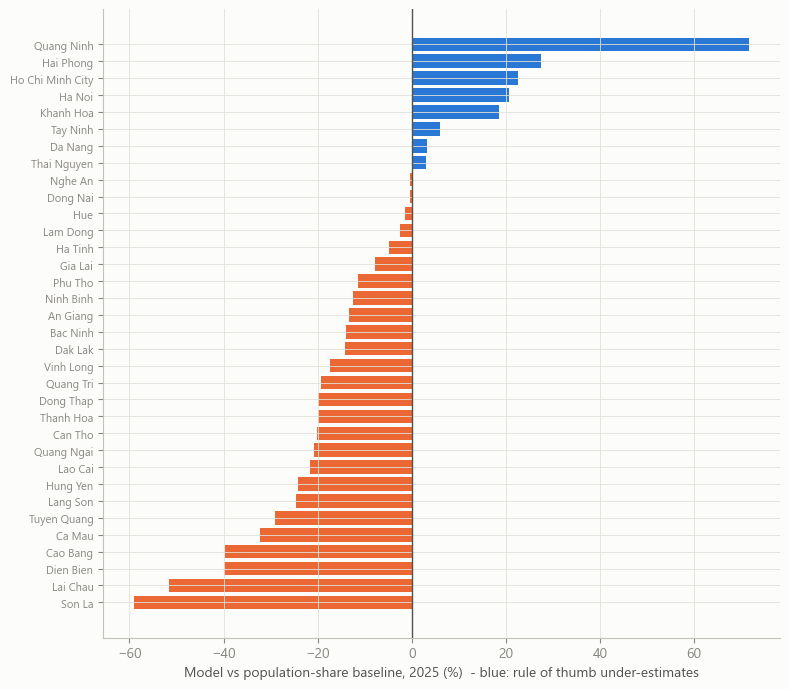

,province_en,baseline_population_share,model_mc_p50,diff_vs_population_share_pct
14,Son La,"3,154,845.985","1,291,417.707",-59.066
13,Lai Chau,"1,178,840.939","570,831.581",-51.577
12,Dien Bien,"1,569,906.920","943,976.479",-39.871
28,Ho Chi Minh City,"32,469,469.249","39,781,884.635",22.521
3,Hai Phong,"9,761,381.157","12,431,746.253",27.356
2,Quang Ninh,"3,320,335.391","5,700,076.905",71.672


In [43]:
# Model vs population-share allocation, province by province (2025, million litres)
cmpv = cmp.merge(base[["province_code", "province_en"]], on="province_code")
# % difference of the model from the rule of thumb: > 0 = rule of thumb UNDER-estimates the province
s = cmpv.sort_values("diff_vs_population_share_pct")
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(s["province_en"], s["diff_vs_population_share_pct"],
        color=[SEG_COLORS["MCO"] if v > 0 else SEG_COLORS["PCMO"] for v in s["diff_vs_population_share_pct"]])
ax.axvline(0, color=INK2, lw=1)
ax.set_xlabel("Model vs population-share baseline, 2025 (%)  - blue: rule of thumb under-estimates")
ax.tick_params(axis="y", labelsize=8); plt.tight_layout(); plt.show()
cmpv.sort_values("diff_vs_population_share_pct")[["province_en", "baseline_population_share", "model_mc_p50",
                                                  "diff_vs_population_share_pct"]].iloc[[0, 1, 2, -3, -2, -1]]

In [44]:
# Provinces the rule of thumb would mis-prioritise (top 10 by 2025 volume)
top_model = set(cmpv.nsmallest(10, "rank_model_mc_p50").province_en)
top_pop = set(cmpv.nsmallest(10, "rank_baseline_population_share").province_en)
print("in model top 10 only           :", sorted(top_model - top_pop))
print("in population-share top 10 only:", sorted(top_pop - top_model))

in model top 10 only           : ['Lam Dong', 'Tay Ninh']
in population-share top 10 only: ['Bac Ninh', 'Thanh Hoa']


In [45]:
# Final model output: national total with 95% interval, and the priority ranking
nat_out = summ["national"].query("segment == 'TOTAL'")[["year", "litres_p025", "litres_p50", "litres_p975"]]
display(nat_out.assign(**{c: nat_out[c] / 1e6 for c in ["litres_p025", "litres_p50", "litres_p975"]}))
summ["priority"].merge(base[["province_code", "province_en"]], on="province_code")[
    ["priority_rank", "tier", "province_en", "litres_2025_p50", "increment_2025_2028_p50", "prob_top10",
     "growth_focus_segment"]].head(10)

,year,litres_p025,litres_p50,litres_p975
3,2025,169.636,240.738,344.333
7,2026,177.122,250.925,358.141
11,2027,184.861,262.084,372.928
15,2028,193.061,273.785,388.638


,priority_rank,tier,province_en,litres_2025_p50,increment_2025_2028_p50,prob_top10,growth_focus_segment
0,1,A,Ho Chi Minh City,"40,778,467.353","6,754,303.296",1.000,HDMO
1,2,A,Ha Noi,"25,726,869.196","4,068,102.456",1.000,HDMO
2,3,A,Hai Phong,"12,684,985.200","2,378,981.229",1.000,HDMO
3,4,A,Dong Nai,"10,773,710.287","1,335,768.326",1.000,HDMO
4,5,A,Nghe An,"8,393,267.497","1,697,363.779",0.973,HDMO
5,6,A,Ninh Binh,"8,110,797.326","1,048,615.756",1.000,HDMO
6,7,A,Lam Dong,"7,844,799.730","966,401.260",0.967,HDMO
7,8,A,Phu Tho,"7,887,771.745","839,561.022",0.994,HDMO
8,9,A,Bac Ninh,"7,407,456.376","1,204,498.882",0.919,HDMO
9,10,A,Thanh Hoa,"7,270,186.102","921,387.410",0.371,HDMO


## 10. Summary and next steps

In [46]:
# Key results, printed from the objects above (no hand-typed numbers)
tests, det = statistics.run_all(base, py)
t25 = summ["national"].query("segment == 'TOTAL' and year == 2025").iloc[0]
print(f"National demand potential 2025: {t25.litres_p50 / 1e6:.0f} M L (95% {t25.litres_p025 / 1e6:.0f}-{t25.litres_p975 / 1e6:.0f})")
for _, r in tests.iterrows():
    print(f"{r.test[:2]}: p(Holm) = {r.p_holm:.3f} -> {'reject H0' if r.reject_h0 else 'fail to reject H0'}")
print("Assumption checks passed:", int(checks.passed.sum()), "of", len(checks))
fb = fc["backtest_summary"].set_index("variable")
for v, r in fb.iterrows():
    print(f"Forecast {v}: chosen {r.chosen_method}, median province MAPE "
          f"{r[f'median_province_mape_{r.chosen_method}']:.1f}%, national MAPE {r[f'national_mape_{r.chosen_method}']:.1f}%")
print(f"Model vs population share: mean |difference| {metrics['mean_abs_diff_vs_population_share_pct']:.0f}%, "
      f"{metrics['top10_changed_vs_population_share']} top-10 provinces change")

National demand potential 2025: 241 M L (95% 170-344)
H1: p(Holm) = 0.030 -> reject H0
H2: p(Holm) = 1.000 -> fail to reject H0
H3: p(Holm) = 1.000 -> fail to reject H0
Assumption checks passed: 7 of 10
Forecast population_k: chosen drift, median province MAPE 0.4%, national MAPE 0.4%
Forecast road_freight_kt: chosen drift, median province MAPE 13.3%, national MAPE 6.9%
Model vs population share: mean |difference| 20%, 2 top-10 provinces change


**Next steps (weeks 3-4 of the plan)**
* Narrow the most influential assumption (motorbike oil-change interval) with a small workshop survey.
* Replace the modelled car / motorbike split if province-level car registrations become available.
* Finish the dashboard (Streamlit app done; Power BI build guide in `docs/powerbi_guide.md`), write the
  technical report and the executive deck from `reports/findings.md`.
* Production run: `python -m vnlube.pipeline` (weekly scheduled task) keeps all of the above current.